# Lab 09 — Linear Fit with Real Data

*You collect the data yourself. Then you fit a line to it and defend the fit.*

## Objectives

1. Collect a real dataset as a class and load it from a spreadsheet
2. Fit a line with scipy.stats.linregress and interpret every returned value
3. Compute and read residuals
4. Report a slope with an uncertainty, not just a number

## Interactive labs for this week

- [`matrix_multiplication_lab.html`](../interactive/matrix_multiplication_lab.html)

---

In [ ]:
# --- setup: run this cell first, every session ---------------------------------
import builtins as __builtin__
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.functional import *

import torchvision
from torchvision import datasets, models, transforms
from torchvision.models import *

from scipy import stats, signal, integrate
from sympy import Symbol

from skimage import io
from skimage import io as skio
from skimage.transform import resize
from skimage.util import montage
from imageio.v2 import imread

from IPython.display import display, HTML

# One device for the whole notebook. A GPU runtime is faster, but nothing here
# requires one -- switch with Runtime -> Change runtime type -> T4 GPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def GPU(data):
    """A learnable float tensor on the active device."""
    return torch.tensor(data, requires_grad=True, dtype=torch.float, device=device)


def GPU_data(data):
    """A fixed (non-learnable) float tensor on the active device."""
    return torch.tensor(data, requires_grad=False, dtype=torch.float, device=device)


print('Running on:', device)

#Linear Fit with Real Data

Required Tools: Ruler and String

1.   Collect 5 round objects (Wheel, Jar, Frisbee, etc)
2.   For each object measure the diameter and circumfrence and create a table like that shown below.




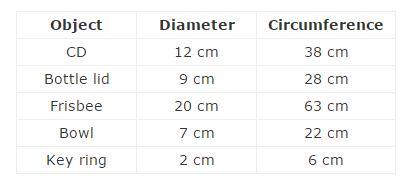

#Replace the values below with the values from your table

In [ ]:
D = np.array([12,9,20,7,2])    # <- Put your numbers here  Diameter
C = np.array([38,28,63,22,6])  #                           Circumference

In [ ]:
plt.plot(D,C,'g.')

In [ ]:
x = D
y = C

In [ ]:
m_guess = 0
b_guess = 0

In [ ]:
x

In [ ]:
m_guess * x

In [ ]:
m_guess * x + b_guess

In [ ]:
y_guess = m_guess * x + b_guess

In [ ]:
y_guess

In [ ]:
best_loss = 1000000000
best_m = 0
best_b = 0

for m_guess in np.linspace(-100,100,100):
    for b_guess in np.linspace(-100,100,100):

        print("Now Testing: ", m_guess, b_guess)

        y_guess = m_guess * x + b_guess

        loss = np.sum((y_guess - y)**2)

        if loss < best_loss:

            best_loss = loss
            best_m = m_guess
            best_b = b_guess

In [ ]:
y_guess = best_m * x + best_b

plt.plot(x,y_guess,'r');
plt.plot(D,C,'g.');
plt.show()

print(best_loss,best_m,best_b)

# Science Example

https://www.youtube.com/watch?v=oAVjF_7ensg

http://depts.washington.edu/astroed/HubbleLaw/galaxies.html

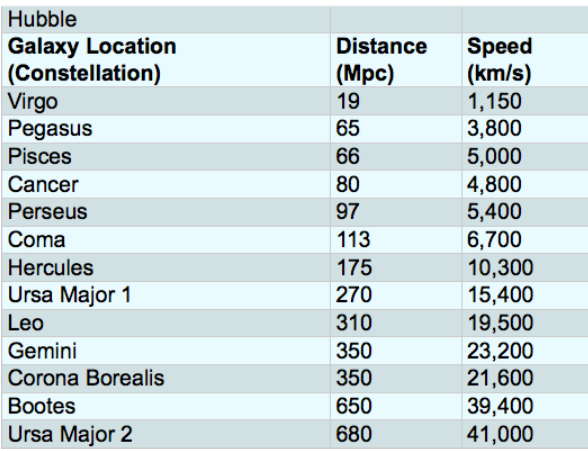

Distance in megaparsecs (Mpc) on the x-axis, and Velocity in kilometers per second (km/s) on the y-axis

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
X = np.array([19,65,66,80,97,113,175,270,310,350,350,650,680])
Y = np.array([1150,3800,5000,4800,5400,6700,10300,15400,19500,23200,21600,39400,41000])

In [ ]:
plt.plot(X,Y,'g.')

In [ ]:
m_guess = 0
b_guess = 0

$y=mx+b$

In [ ]:
m_guess * X + b_guess

In [ ]:
y_guess = m_guess * X + b_guess

In [ ]:
y_guess - Y

In [ ]:
np.sum((y_guess - Y)**2)

In [ ]:
loss = np.sum((y_guess - Y)**2)

In [ ]:
best_loss_so_far = 1000000000000
m_best = 0
b_best = 0
for m_guess in np.linspace(-100,100,100):
    for b_guess in np.linspace(-100,100,100):

        y_guess = m_guess * X + b_guess

        loss = np.sum((y_guess - Y)**2)

        if loss < best_loss_so_far:
            m_best = m_guess
            b_best = b_guess
            best_loss_so_far = loss

print("Found best fit:")
print(m_best,b_best,loss)

In [ ]:
m_best

In [ ]:
H = m_best

In [ ]:
1/H

If the universe has been expanding since its beginning at a constant speed, the universe's age would simply be 1/Ho.
Find the inverse of your value of Ho.
Multiply the inverse by $3.09 \times 10^{19}$ km/Mpc to cancel the distance units.
Since you now have the age of the Universe in seconds, divide this number by the number of seconds in a year: $3.16 \times 10^{7}$ sec/yr.

$3.09 \times 10^{19}$ km/Mpc

$3.16 \times 10^{7}$ sec/year

In [ ]:
(1/H) * (3.09*10**19)

In [ ]:
(1/H) * (3.09*10**19)  / (3.16*10**7)

In [ ]:
 (1/H) * (3.09*10**19)  / (3.16*10**7) / (1000000000)

#Data Collection Spreadsheet

https://docs.google.com/spreadsheets/d/1lQFXhUEEPQulgi_19VvEwH7Qw_N-2rPNRJBHO7gfPwk/edit?usp=sharing

http://depts.washington.edu/astroed/HubbleLaw/galaxies.html

https://docs.google.com/spreadsheets/d/1B_HW2uVGQv9W7b6vVZDSkOPLtmfodHrX4G0qtQbIenk/edit?usp=sharing

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
def get_database(url,sheet_name):
    url_head = "https://docs.google.com/spreadsheets/d/"
    url_foot = "/gviz/tq?tqx=out:csv&sheet="
    url_body = url.split('/')[5]
    # sheet_name = "1"
    url_csv = url_head + url_body + url_foot + sheet_name
    df = pd.read_csv(url_csv, sep=',', skiprows=0)
    return df

In [ ]:
url = 'https://docs.google.com/spreadsheets/d/1B_HW2uVGQv9W7b6vVZDSkOPLtmfodHrX4G0qtQbIenk/edit?usp=sharing'

In [ ]:
sheet_name = 'Distance'

In [ ]:
Distance_data = get_database(url,sheet_name)

In [ ]:
Distance_data = np.array(Distance_data)[:,1:]

In [ ]:
Distance_data.shape

In [ ]:
Distance_data = np.mean(Distance_data,1)

In [ ]:
Distance_data

In [ ]:
sheet_name = 'Velocity'

In [ ]:
Velocity_data = get_database(url,sheet_name)

In [ ]:
Velocity_data

In [ ]:
Velocity_data = np.array(Velocity_data)[:,1:]

In [ ]:
Velocity_data.shape

In [ ]:
Velocity_data = np.mean(Velocity_data,1)

In [ ]:
Velocity_data

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
X = np.array([19,65,66,80,97,113,175,270,310,350,350,650,680])
Y = np.array([1150,3800,5000,4800,5400,6700,10300,15400,19500,23200,21600,39400,41000])

In [ ]:
X = Distance_data
Y = Velocity_data

In [ ]:
plt.plot(X,Y,'g.')

In [ ]:
m_guess = 0
b_guess = 0

$y=mx+b$

In [ ]:
m_guess * X + b_guess

In [ ]:
y_guess = m_guess * X + b_guess

In [ ]:
y_guess - Y

In [ ]:
np.sum((y_guess - Y)**2)

In [ ]:
loss = np.sum((y_guess - Y)**2)

In [ ]:
best_loss_so_far = 1000000000000
m_best = 0
b_best = 0
for m_guess in np.linspace(-100,100,100):
    for b_guess in np.linspace(-100,100,100):

        y_guess = m_guess * X + b_guess

        loss = np.sum((y_guess - Y)**2)

        if loss < best_loss_so_far:
            m_best = m_guess
            b_best = b_guess
            best_loss_so_far = loss

print("Found best fit:")
print(m_best,b_best,loss)

In [ ]:
m_best

In [ ]:
H = m_best

In [ ]:
1/H

If the universe has been expanding since its beginning at a constant speed, the universe's age would simply be 1/Ho.
Find the inverse of your value of Ho.
Multiply the inverse by $3.09 \times 10^{19}$ km/Mpc to cancel the distance units.
Since you now have the age of the Universe in seconds, divide this number by the number of seconds in a year: $3.16 \times 10^{7}$ sec/yr.

$3.09 \times 10^{19}$ km/Mpc

$3.16 \times 10^{7}$ sec/year

In [ ]:
(1/H) * (3.09*10**19)

In [ ]:
(1/H) * (3.09*10**19)  / (3.16*10**7)

In [ ]:
 (1/H) * (3.09*10**19)  / (3.16*10**7) / (1000000000)

---

## Homework

1. Collect at least 20 paired measurements of something physical. Fit a line. Report slope, r-value, and residuals.
2. State plainly what the slope means in the units of your experiment.

Submit as a markdown report in your course GitHub repo, with plots committed alongside it.

<details><summary>Where this lab came from</summary>

- `_source/notebooks/Math24/Lab_6__1_Z8yjN6.ipynb` cells 17–105 (79 kept)

</details>